In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import random
import os
import keras

In [2]:
from keras.optimizers import Adam
from keras.layers import Dense, Input
from keras.models import Sequential
from collections import deque

#seed configuration

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

In [4]:
cust_map = [
    'SFFF',
    'FHFH',
    'HFFF',
    'HFFG'
]

env = gym.make('FrozenLake-v1', desc = cust_map, is_slippery = False)

episodes = 1000
test_episodes = 100
max_steps = 100
batch_size = 32
target_update_freq = 25

state_size = int(env.observation_space.n)
action_size = int(env.action_space.n)

def to_one_hot(obs: int, size: int) -> np.ndarray:
    arr = np.zeros((1, size), dtype=np.float32)
    arr[0, obs] = 1.0
    return arr

#dqn class and functions and intializations

In [5]:
class DQN:
    def __init__(self, state_size, action_size):
        self.state_size = state_size
        self.action_size = action_size

        self.memory = deque(maxlen = 5000)
        self.learning_rate = 0.001
        self.gamma = 0.95

        self.epsilon = 1
        self.max_eps = 1
        self.min_eps = 0.01
        self.eps_decay = 0.005
        self.epsilon_lst = []

        self.model = self._build_model()
        self.target_model = self._build_model()
        self.update_target_model()

    def _build_model(self) -> Sequential:
        model = Sequential([
            Input(shape=(self.state_size,)),
            Dense(32, activation="relu"),
            Dense(32, activation="relu"),
            Dense(self.action_size, activation="linear")
        ])
        model.compile(loss = 'mse', optimizer = Adam(learning_rate = self.learning_rate))
        return model

    def update_target_model(self):
        self.target_model.set_weights(self.model.get_weights())

    def remember(self, state, action, reward, next_state, done):
        self.memory.append((state, action, reward, next_state, done))

    def select_action(self, state: np.ndarray) -> int:
        if np.random.rand() < self.epsilon:
            return np.random.randint(0, self.action_size)
        return self.predict_action(state)

    def predict_action(self, state: np.ndarray) -> int:
        q_values = self.model(state, training=False).numpy()
        return int(np.argmax(q_values[0]))

    def replay(self, batch_size: int, episode: int):
        if len(self.memory) < batch_size:
            return

        minibatch = random.sample(self.memory, batch_size)
        
        states = np.vstack([x[0] for x in minibatch])
        actions = np.array([x[1] for x in minibatch], dtype=np.int32)
        rewards = np.array([x[2] for x in minibatch], dtype=np.float32)
        next_states = np.vstack([x[3] for x in minibatch])
        dones = np.array([x[4] for x in minibatch], dtype=bool)

        current_q = self.model(states, training=False).numpy()
        next_q = self.target_model(next_states, training=False).numpy()

        max_next_q = np.amax(next_q, axis=1)
        targets = rewards + self.gamma * max_next_q * (~dones)

        target_f = current_q.copy()
        target_f[np.arange(batch_size), actions] = targets

        self.model.train_on_batch(states, target_f)

        self.epsilon = (self.max_eps - self.min_eps) * np.exp(-self.eps_decay * episode) + self.min_eps
        self.epsilon_lst.append(self.epsilon)

    def save(self, filepath: str):
        self.model.save_weights(filepath)

    def load(self, filepath: str):
        self.model.load_weights(filepath)
        self.update_target_model()

#training the deep-q network

In [6]:
agent = DQN(state_size, action_size)
reward_lst = []

for episode in range(episodes):
    obs, _ = env.reset()
    state = to_one_hot(obs, state_size)
    ep_reward = 0.0

    for _ in range(max_steps):
        action = agent.select_action(state)
        next_obs, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        next_state = to_one_hot(next_obs, state_size)
        agent.remember(state, action, reward, next_state, done)

        state = next_state
        ep_reward += reward

        if done:
            break

    reward_lst.append(ep_reward)
    agent.replay(batch_size, episode)

    if (episode + 1) % target_update_freq == 0:
        agent.update_target_model()

print(f"Training Mean % Score = {100 * np.mean(reward_lst):.1f}%")

Training Mean % Score = 73.7%


#evaluation

In [7]:
eval_reward_lst = []

for _ in range(test_episodes):
    obs, _ = env.reset()
    state = to_one_hot(obs, state_size)
    ep_reward = 0.0

    for _ in range(max_steps):
        action = agent.predict_action(state)
        next_obs, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        state = to_one_hot(next_obs, state_size)
        ep_reward += reward

        if done:
            break

    eval_reward_lst.append(ep_reward)

print(f"Evaluation Mean % Score = {100 * np.mean(eval_reward_lst):.1f}%")

Evaluation Mean % Score = 100.0%


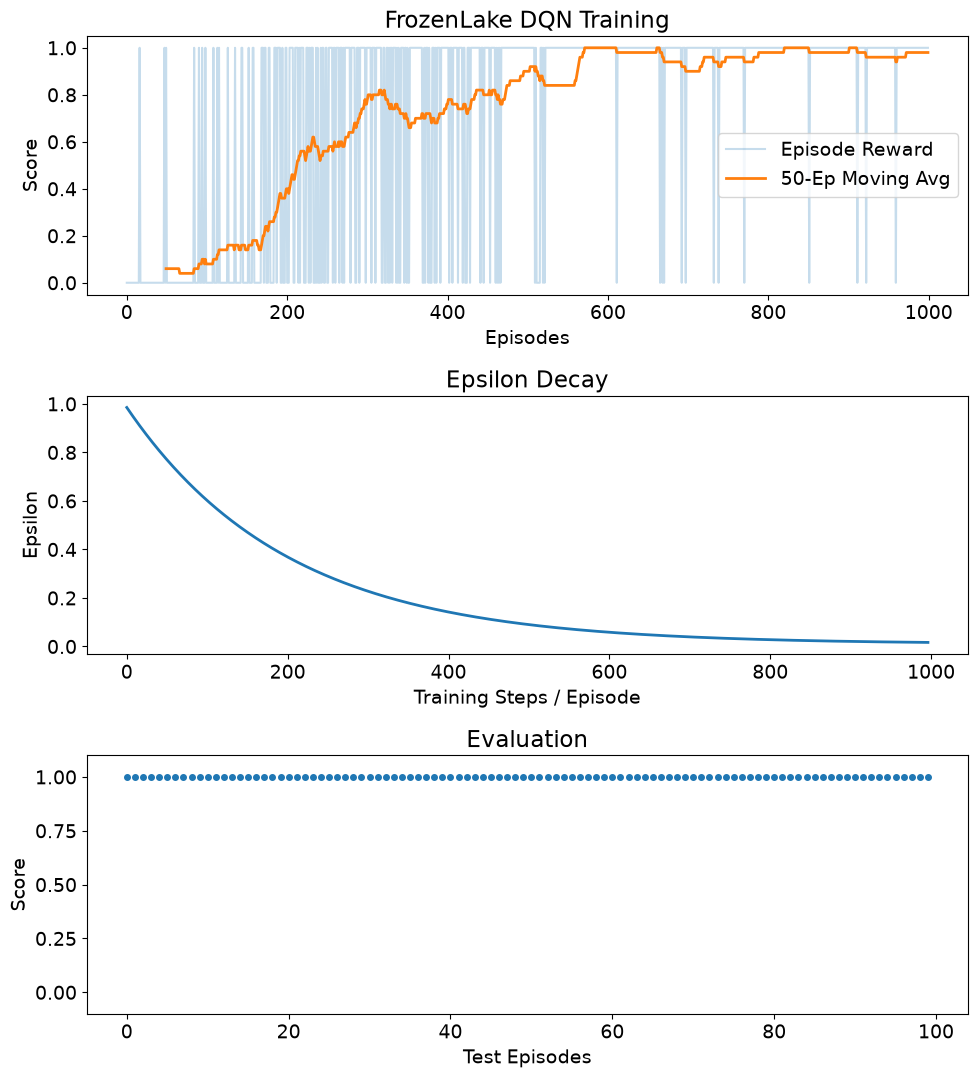

In [8]:
plt.rcParams.update({"font.size": 14})
fig, axes = plt.subplots(3, 1, figsize=(10, 11))

#1. training rewards (rolling average)
window = 50
rolling_avg = np.convolve(reward_lst, np.ones(window) / window, mode="valid")
axes[0].plot(reward_lst, alpha=0.25, label="Episode Reward")
axes[0].plot(range(window - 1, len(reward_lst)), rolling_avg, linewidth=2, label=f"{window}-Ep Moving Avg")
axes[0].set_title("FrozenLake DQN Training")
axes[0].set_xlabel("Episodes")
axes[0].set_ylabel("Score")
axes[0].legend()

#2. epsilon decay
axes[1].plot(agent.epsilon_lst, linewidth=2)
axes[1].set_title("Epsilon Decay")
axes[1].set_xlabel("Training Steps / Episode")
axes[1].set_ylabel("Epsilon")

axes[2].plot(eval_reward_lst, marker="o", linestyle="", markersize=4)
axes[2].set_ylim(-0.1, 1.1)
axes[2].set_title("Evaluation")
axes[2].set_xlabel("Test Episodes")
axes[2].set_ylabel("Score")

plt.tight_layout()
plt.show()